In [1]:
import os
import re
import time
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from collections import Counter, defaultdict
from torch.utils.data import DataLoader, TensorDataset

# PARAMETRI

In [2]:
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [3]:
from datasets.datasets import load_PROMESSI_SPOSI
text = load_PROMESSI_SPOSI()
print(f"CARATTERI: {len(text)}")
print(text[:300], "...\n")

LOOK_BACK = 20          # parole lette per predire la successiva
VOCAB_SIZE = 10000      # parole più frequenti nel dizionario: le altre diventano <unk>
TRAIN_SPLIT = 0.9       # la prima parte del romanzo per il training, l'ultima per il test

# TOKENIZZAZIONE: parole (con l'apostrofo, come "dell'" e "po'") e segni di punteggiatura, tutto minuscolo
TOKEN_PATTERN = r"\w+'|\w+|\.{2,}|[^\w\s]"
tokens_original = re.findall(TOKEN_PATTERN, text)
tokens = [t.lower() for t in tokens_original]
print(f"TOKEN: {len(tokens)}, DISTINTI: {len(set(tokens))}")
print(tokens[:25], "\n")

# DIZIONARIO: parola -> indice, in ordine di frequenza; l'indice 0 è riservato alle parole rare
counts = Counter(tokens)
idx2word = ['<unk>'] + [w for w, _ in counts.most_common(VOCAB_SIZE - 1)]
word2idx = {w: i for i, w in enumerate(idx2word)}
UNK = 0
ids = np.array([word2idx.get(t, UNK) for t in tokens])
print(f"DIZIONARIO: {len(idx2word)} parole, che coprono il {np.mean(ids != UNK):.1%} del testo")
print(f"LE PIÙ FREQUENTI: {idx2word[1:21]}\n")

# Per stampare il testo generato: la forma più frequente di ogni parola nel testo originale ("renzo" -> "Renzo")
forms = defaultdict(Counter)
for t in tokens_original:
    forms[t.lower()][t] += 1
display_form = {w: c.most_common(1)[0][0] for w, c in forms.items()}

# Esempi supervisionati: LOOK_BACK parole consecutive -> parola successiva, come le finestre della serie temporale
windows = np.lib.stride_tricks.sliding_window_view(ids, LOOK_BACK + 1)   # (esempi, LOOK_BACK + 1)
x, y = windows[:, :-1].copy(), windows[:, -1].copy()

# Split nel tempo: il test è la parte finale del romanzo, mai vista durante il training
train_size = int(len(x) * TRAIN_SPLIT)
train_dataset = TensorDataset(torch.tensor(x[:train_size]), torch.tensor(y[:train_size]))
test_dataset = TensorDataset(torch.tensor(x[train_size:]), torch.tensor(y[train_size:]))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"SHAPE: X_TRAIN = {tuple(train_dataset.tensors[0].shape)}, Y_TRAIN = {tuple(train_dataset.tensors[1].shape)}")
print(f"SHAPE: X_TEST = {tuple(test_dataset.tensors[0].shape)}, Y_TEST = {tuple(test_dataset.tensors[1].shape)}")
print(f"ESEMPIO: {' '.join(idx2word[i] for i in x[0])}  ->  {idx2word[y[0]]}")

CARATTERI: 456100
Quel ramo del lago di Como che volge a mezzogiorno, tra due catene non interrotte di monti, tutto a seni e a golfi, a seconda dello sporgere e del rientrare di quelli (tali notizie noi ricaviamo da un Manoscritto del Milleseicento, nel quale è narrata la presente istoria) è un lago esclusivamente d' ...

TOKEN: 90948, DISTINTI: 13476
['quel', 'ramo', 'del', 'lago', 'di', 'como', 'che', 'volge', 'a', 'mezzogiorno', ',', 'tra', 'due', 'catene', 'non', 'interrotte', 'di', 'monti', ',', 'tutto', 'a', 'seni', 'e', 'a', 'golfi'] 

DIZIONARIO: 10000 parole, che coprono il 96.2% del testo
LE PIÙ FREQUENTI: [',', 'di', '.', 'e', 'che', '-', 'il', 'la', 'a', 'un', 'non', 'per', 'in', 'si', 'le', ';', 'con', "l'", '!', 'del']

SHAPE: X_TRAIN = (81835, 20), Y_TRAIN = (81835,)
SHAPE: X_TEST = (9093, 20), Y_TEST = (9093,)
ESEMPIO: quel ramo del lago di como che volge a mezzogiorno , tra due catene non interrotte di monti , tutto  ->  a


# MODELLO

In [4]:
#Parametri del modello
EMBEDDING_DIM = 128
HIDDEN_SIZE = 256
DROPOUT = 0.3

In [5]:
# nn.LSTM restituisce (output, (h, c)), quindi non si può mettere direttamente in un nn.Sequential
class WordLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)   # ogni indice di parola -> vettore da embedding_dim valori
        self.lstm = nn.LSTM(embedding_dim, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):                              # (B, LOOK_BACK) indici delle parole
        x = self.embedding(x)                          # (B, LOOK_BACK, EMBEDDING_DIM)
        out, _ = self.lstm(x)                          # (B, LOOK_BACK, HIDDEN_SIZE)
        return self.fc(self.dropout(out[:, -1]))       # uscita dell'ultimo passo -> un logit per parola (B, VOCAB_SIZE)

torch.manual_seed(7)
model = WordLSTM(len(idx2word), EMBEDDING_DIM, HIDDEN_SIZE, DROPOUT).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()     # predire la parola successiva è una classificazione con VOCAB_SIZE classi

print(model)
print(f"Parametri: {sum(p.numel() for p in model.parameters())}")

WordLSTM(
  (embedding): Embedding(10000, 128)
  (lstm): LSTM(128, 256, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=10000, bias=True)
)
Parametri: 4245264


# ADDESTRAMENTO

  0%|          | 0/20 [00:00<?, ?it/s]

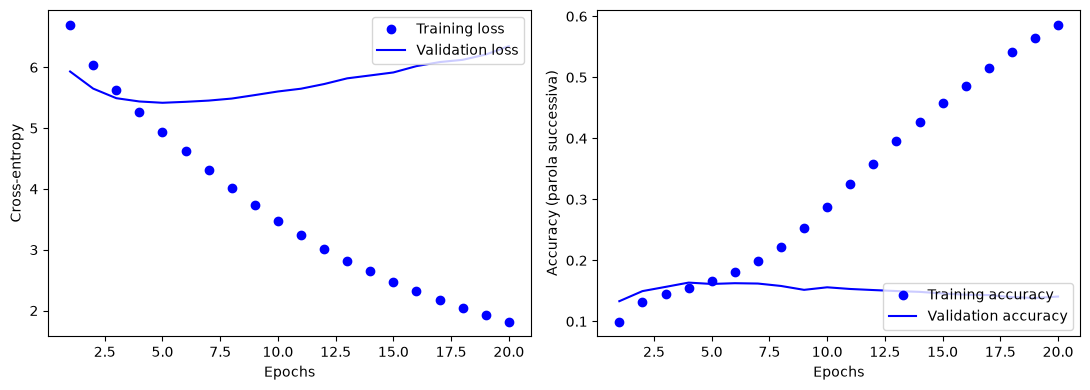

In [6]:
os.makedirs('histories', exist_ok=True)
filename = "text_generation"

hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history = pickle.load(hist_file)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history = utils.train(model, optimizer, criterion, train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history, hist_file)
    torch.save(model.state_dict(), weights_path)

epochs = range(1, len(history['loss']) + 1)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['loss'], 'bo', label='Training loss')
plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Cross-entropy')
plt.legend(loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(epochs, history['accuracy'], 'bo', label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], 'b', label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (parola successiva)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# VALUTAZIONE

In [10]:
def predict(model, dataset, batch_size=1024):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in DataLoader(dataset, batch_size=batch_size, shuffle=False):
            preds.append(model(x.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

x_test, y_test = test_dataset.tensors[0].numpy(), test_dataset.tensors[1].numpy()
print(f"ACCURACY: {np.mean(predict(model, test_dataset) == y_test)}")


ACCURACY: 0.14065764874078962


# GENERAZIONE

In [11]:
# GENERAZIONE AUTOREGRESSIVA: la rete predice una parola, la aggiunge al testo e la usa per predire la successiva

def generate(model, seed, n_words=100, temperature=0.8, delay=0.05):
    model.eval()
    tokens = [t.lower() for t in re.findall(TOKEN_PATTERN, seed)]
    context = [word2idx.get(t, UNK) for t in tokens]
    for token in tokens:                                         # il seme
        print(token, end=' ')
    for _ in range(n_words):
        x = torch.tensor([context[-LOOK_BACK:]], device=DEVICE)    # le ultime LOOK_BACK parole
        with torch.no_grad():
            logits = model(x)[0]
        logits[UNK] = -float('inf')                              # mai generare <unk>
        if temperature == 0:
            idx = logits.argmax().item()                         # sempre la parola più probabile
        else:
            probs = torch.softmax(logits / temperature, dim=0)
            idx = torch.multinomial(probs, 1).item()             # una parola estratta secondo le probabilità
        context.append(idx)                                      # la parola generata entra nel contesto
        token = idx2word[idx]
        print(token, end=' ', flush=True)                          # una parola alla volta
        time.sleep(delay)
    print()

torch.manual_seed(0)
generate(model, "Quel ramo del lago di Como", n_words=150)

Quel ramo del lago di Como divini, con quel vecchio forze i centosessant'anni suonati, incominciasse gradatamente a sentire, e quasi soddisfece; ai birri, le donne che hanno passata una magnifica ai notte, prese la sporta in gambe. Ma ora che i contadini si aveva lasciata altre uomini, e promettendogli, in mezzo, con la corte della sua camicia, e, come nella sua assenza, aveva sempre torto in auto, e, per un angolo di tumulto, la quale commentava sfavorevolmente l'arresto. Ma, don Rodrigo, pensando, che verso il nome: se il sapea, gli evviva stessi, i suoi bravi, le tasse donne che hanno le sue unghie a parlar col re di Francia, si precipitaron a capofitto gli si accinse a rodere quattro sul poco, e una ciambella come i due,


In [12]:
# TEMPERATURA: divide i logit prima della softmax.
# Bassa = parole più probabili, testo prevedibile e ripetitivo; alta = testo più vario ma meno coerente
for temperature in [0, 0.5, 1.0, 1.5]:
    print(f"\n--- temperatura {temperature} ---")
    torch.manual_seed(0)
    generate(model, "Renzo", n_words=60, temperature=temperature, delay=0.02)


--- temperatura 0 ---
Renzo tirava come Dio volle... - ma io non so cavalcare, - rispose Lucia. - ma che fiabe le soli mo' queste? - domandò, con la finta! - il Cardinale, che a quel tempo è amante di quel tonto e povero don Rodrigo, senza dare il mezzo di sottrarsi, per un velenario

--- temperatura 0.5 ---
Renzo pronunziare innamorato cotto per aiuto spirituale la Signora donna Prassede, la quale lo pregava di far accettare, se ne tornò a spron battuto verso la strada, il quale venne bastonato, la recupera: - e che, se io veggo una locomotiva, non è la Provvidenza che non è lui. - nemmeno quel che

--- temperatura 1.0 ---
Renzo divini sgangherato insistente avresti compenso amorevole mentito moltissimo donna cantando nero andrai Garibaldi furon bensì le proprie dell'altrui che, sotto la folla delle allodole. Ad una ragione di gran dama, più in mezzo si metteva. Poi a quest'ora un demonio detto il grande della capitano di giustizia. Stante non possiamo che di bagnarsi

--- temperatur

![Testo alternativo](imgs/temperatura.png)
